# SkillCorner Body Pose Visualization Example

This notebook demonstrates some examples of using the visualizer code located here: https://github.com/MattLowrieDS/skillcorner_pose_viz

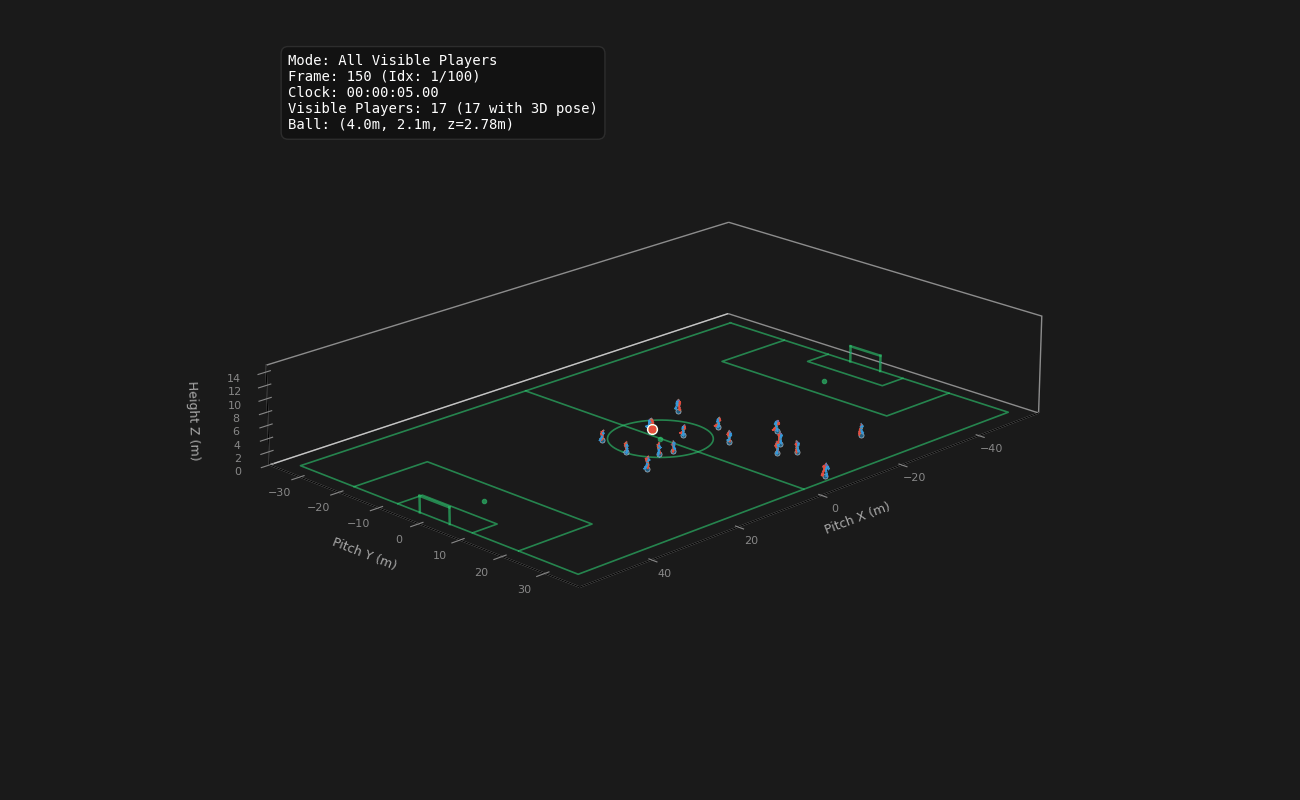

In [ ]:
# You will need to add a Hugging Face auth token with the name HF_TOKEN
# in the "Secrets" section of the Colab sidebar options
!hf update && hf download SkillCorner/opendata-bodypose --repo-type dataset --local-dir .

Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Current version: 1.33.0
Checking for updates to latest version...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 10.4 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
Hint: Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
Reconstructing (incomplete total...): |          |  0.00B /  0.00B  

In [ ]:
!git clone https://github.com/SkillCorner/opendata.git
!git clone https://github.com/MattLowrieDS/skillcorner_pose_viz.git

Cloning into 'opendata'...
remote: Enumerating objects: 696, done.
remote: Counting objects: 100% (134/134), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 696 (delta 103), reused 89 (delta 89), pack-reused 562 (from 1)
Receiving objects: 100% (696/696), 181.23 MiB | 13.51 MiB/s, done.
Resolving deltas: 100% (312/312), done.
Cloning into 'skillcorner_pose_viz'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 16 (delta 2), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 5.59 MiB | 21.68 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [ ]:
!cd raw && unzip -o 1925299.jsonl.zip
!cd raw && unzip -o 1996435.jsonl.zip

Archive:  1925299.jsonl.zip
  inflating: 1925299.jsonl           
  inflating: __MACOSX/._1925299.jsonl  
Archive:  1996435.jsonl.zip
  inflating: 1996435.jsonl           
  inflating: __MACOSX/._1996435.jsonl  


In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import Image, display
import skillcorner_pose_viz.animate as bpviz
from opendata.src.data import pose_loading

In [ ]:
# Find all shot events from match
match_id = 1925299

# Brisbane Roar v Perth Glory, 2024-12-21
dynev_df = pl.read_csv(f'opendata/data/matches/{match_id}/{match_id}_dynamic_events.csv')

shots_df = (dynev_df.filter(
    pl.col('event_type') == 'player_possession',
    pl.col('end_type') == 'shot',
).with_row_index(name='shot_id', offset=0))

with pl.Config(tbl_rows=-1, tbl_cols=-1):
  print(shots_df['shot_id', 'period', 'time_start', 'time_end', 'frame_start', 'frame_end', 'player_id'])

shape: (30, 7)
┌─────────┬────────┬────────────┬──────────┬─────────────┬───────────┬───────────┐
│ shot_id ┆ period ┆ time_start ┆ time_end ┆ frame_start ┆ frame_end ┆ player_id │
│ ---     ┆ ---    ┆ ---        ┆ ---      ┆ ---         ┆ ---       ┆ ---       │
│ u32     ┆ i64    ┆ str        ┆ str      ┆ i64         ┆ i64       ┆ i64       │
╞═════════╪════════╪════════════╪══════════╪═════════════╪═══════════╪═══════════╡
│ 0       ┆ 1      ┆ 05:55.6    ┆ 05:55.6  ┆ 3566        ┆ 3566      ┆ 560882    │
│ 1       ┆ 1      ┆ 09:23.8    ┆ 09:24.9  ┆ 5648        ┆ 5659      ┆ 966112    │
│ 2       ┆ 1      ┆ 18:34.9    ┆ 18:36.2  ┆ 11159       ┆ 11172     ┆ 966114    │
│ 3       ┆ 1      ┆ 22:48.6    ┆ 22:48.6  ┆ 13696       ┆ 13696     ┆ 560989    │
│ 4       ┆ 1      ┆ 24:36.1    ┆ 24:37.2  ┆ 14771       ┆ 14782     ┆ 797298    │
│ 5       ┆ 1      ┆ 26:20.7    ┆ 26:21.9  ┆ 15817       ┆ 15829     ┆ 966112    │
│ 6       ┆ 1      ┆ 26:31.0    ┆ 26:31.7  ┆ 15920       ┆ 15927     ┆ 5

[*] Building frame index for 1925299.jsonl...
[✓] Indexed 153,252 frames in 1.32s -> cached to .cache/1925299.jsonl.idx.npy


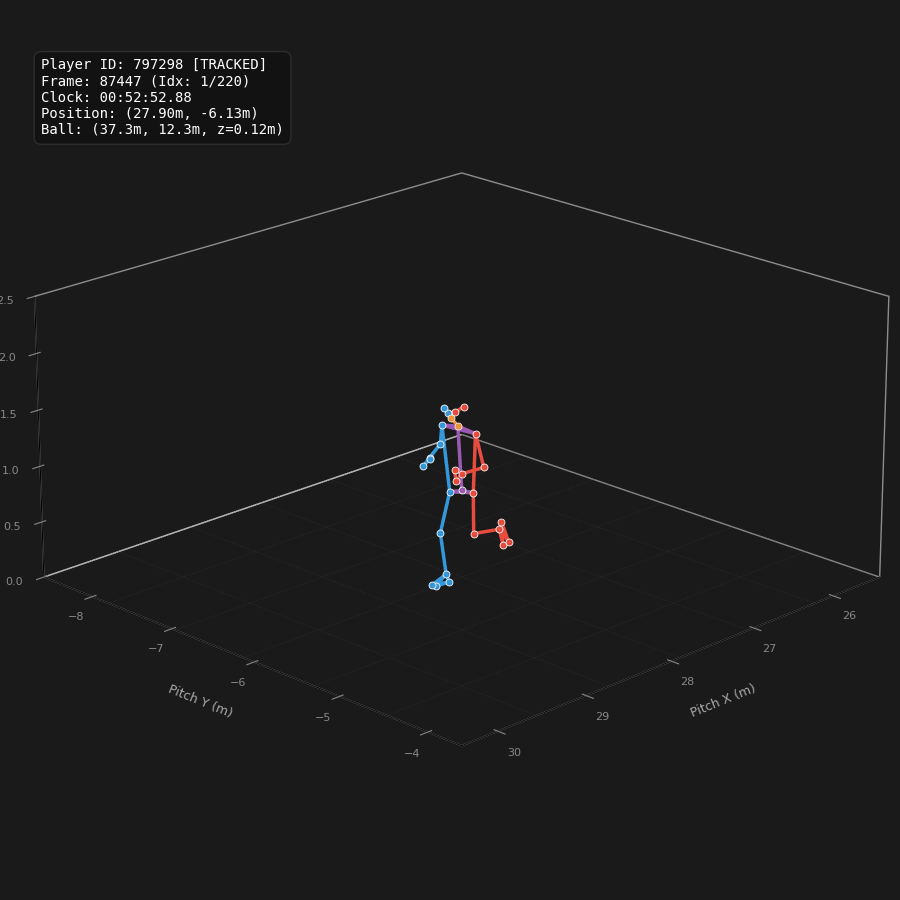

In [ ]:
# Animate one of the players taking a (missed) shot during the match
shot_id = 14
frame_padding = 110
track_frame_id = shots_df['frame_start'][shot_id]
pose_frame_id = int(pose_loading.tracking_to_pose_frame(track_frame_id))
player_id = shots_df['player_id'][shot_id]

anim = bpviz.animate_soccer_pose(
    path_to_jsonl=f'/content/raw/{match_id}.jsonl',
    start_frame=pose_frame_id - frame_padding,
    num_frames=frame_padding * 2,
    player_id=player_id,
)

# Close the active matplotlib figure to suppress the inline static frame output
plt.close()

gif_path = 'pose_viz1.gif'
anim.save(gif_path, writer='pillow', fps=pose_loading.POSE_FPS)

display(Image(filename=gif_path))

[*] Building frame index for 1996435.jsonl...
[✓] Indexed 144,052 frames in 0.89s -> cached to .cache/1996435.jsonl.idx.npy


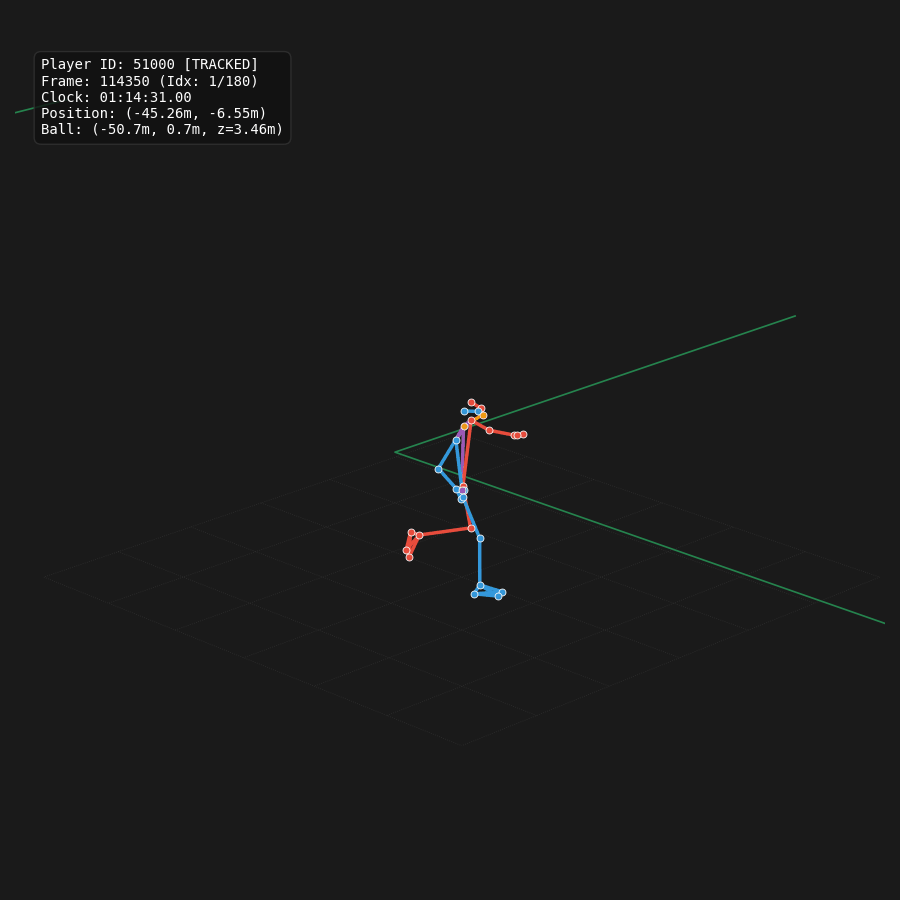

In [ ]:
# Example of frames where the pose data is "confused"
anim = bpviz.animate_soccer_pose(
    path_to_jsonl='/content/raw/1996435.jsonl',
    start_frame=114350,
    num_frames=180,
    player_id=51000,
    no_axis=True,
)

plt.close()

gif_path = 'pose_viz.gif'
anim.save(gif_path, writer='pillow', fps=pose_loading.POSE_FPS)
display(Image(filename=gif_path))